# Abbandono clienti e stagionalita' - Online Retail II

Notebook di analisi statistica sulla segmentazione RFM (`data/processed/customer_rfm.csv`): confronto tra segmenti a diverso rischio di abbandono su Frequency e Monetary, e analisi delle correlazioni tra Recency, Frequency e Monetary.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)

## 1. Caricamento dati

Il file `customer_rfm.csv` e' generato dal notebook `02_rfm_segmentation` con alcune particolarita' da gestire in lettura:
- separatore `;` invece della virgola,
- nessuna riga di intestazione (le colonne sono nell'ordine `CustomerID, Recency, Frequency, Monetary, Segment`),
- presenza di un BOM UTF-8 a inizio file (gestito con `encoding="utf-8-sig"`).

In [2]:
RFM_PATH = "../../data/processed/customer_rfm.csv"

rfm = pd.read_csv(
    RFM_PATH,
    sep=";",
    header=None,
    names=["CustomerID", "Recency", "Frequency", "Monetary", "Segment"],
    encoding="utf-8-sig",
)

segment_order = ["Top", "Fedele", "A rischio", "Perso"]
rfm["Segment"] = pd.Categorical(rfm["Segment"], categories=segment_order, ordered=True)

print(f"Clienti: {len(rfm):,}")
rfm.head()

Clienti: 5,878


,CustomerID,Recency,Frequency,Monetary,Segment
0,12346,529,11,372.86,A rischio
1,12347,2,8,4921.53,Top
2,12348,75,5,2019.40,Top
3,12349,19,4,4428.69,Top
4,12350,310,1,334.40,Perso


In [3]:
rfm["Segment"].value_counts().reindex(segment_order)

Segment
Top          1814
Fedele        441
A rischio    1159
Perso        2464
Name: count, dtype: int64

In [4]:
rfm.groupby("Segment", observed=True)[["Recency", "Frequency", "Monetary"]].agg(["mean", "median"])

Recency         Frequency            Monetary          
                 mean median       mean median         mean    median
Segment                                                              
Top         29.045755   22.0  14.095921    9.0  7254.761680  3097.625
Fedele      37.995465   33.0   3.278912    3.0  1060.700163   822.570
A rischio  295.685936  267.0   5.493529    4.0  2302.153457  1313.670
Perso      313.186688  323.0   1.454545    1.0   338.087967   304.250

## 2. Confronto statistico tra segmenti

Raggruppiamo i quattro segmenti in due macro-gruppi, come richiesto:
- **Fedele/Top**: clienti ad alto valore e basso rischio di abbandono.
- **A rischio/Perso**: clienti a rischio di abbandono o gia' inattivi.

Confrontiamo i due gruppi su `Frequency` e `Monetary`. Prima di scegliere il test d'ipotesi verifichiamo la normalita' delle due distribuzioni con il test di **Shapiro-Wilk**: se entrambe le distribuzioni sono compatibili con una normale usiamo un **t-test di Welch** (non assume varianze uguali), altrimenti un test non parametrico **Mann-Whitney U**, robusto a distribuzioni asimmetriche e outlier - condizione tipica dei dati di spesa/frequenza d'acquisto.

In [5]:
group_map = {
    "Top": "Fedele/Top",
    "Fedele": "Fedele/Top",
    "A rischio": "A rischio/Perso",
    "Perso": "A rischio/Perso",
}
rfm["Gruppo"] = rfm["Segment"].map(group_map)

rfm["Gruppo"].value_counts()

Gruppo
A rischio/Perso    3623
Fedele/Top         2255
Name: count, dtype: int64

In [6]:
def format_pvalue(p):
    return "< 0.001" if p < 0.001 else f"{p:.4f}"


def confronta_segmenti(metric, alpha=0.05):
    g1 = rfm.loc[rfm["Gruppo"] == "Fedele/Top", metric]
    g2 = rfm.loc[rfm["Gruppo"] == "A rischio/Perso", metric]

    shapiro_g1 = stats.shapiro(g1)
    shapiro_g2 = stats.shapiro(g2)
    print(f"--- {metric} ---")
    print(f"Shapiro-Wilk Fedele/Top:      stat={shapiro_g1.statistic:.4f}  p={format_pvalue(shapiro_g1.pvalue)}")
    print(f"Shapiro-Wilk A rischio/Perso: stat={shapiro_g2.statistic:.4f}  p={format_pvalue(shapiro_g2.pvalue)}")

    normali = shapiro_g1.pvalue > alpha and shapiro_g2.pvalue > alpha
    if normali:
        print("Entrambe le distribuzioni sono compatibili con una normale -> t-test di Welch")
        test = stats.ttest_ind(g1, g2, equal_var=False)
        nome_test = "Welch t-test"
    else:
        print("Almeno una distribuzione non e' normale -> test non parametrico Mann-Whitney U")
        test = stats.mannwhitneyu(g1, g2, alternative="two-sided")
        nome_test = "Mann-Whitney U"

    print(f"{nome_test}: stat={test.statistic:.2f}  p={format_pvalue(test.pvalue)}")
    print(f"Mediana Fedele/Top: {g1.median():.2f}  |  Mediana A rischio/Perso: {g2.median():.2f}")
    print(f"Media   Fedele/Top: {g1.mean():.2f}  |  Media   A rischio/Perso: {g2.mean():.2f}")
    print()
    return test

In [7]:
risultato_frequency = confronta_segmenti("Frequency")

--- Frequency ---
Shapiro-Wilk Fedele/Top:      stat=0.3992  p=< 0.001
Shapiro-Wilk A rischio/Perso: stat=0.3645  p=< 0.001
Almeno una distribuzione non e' normale -> test non parametrico Mann-Whitney U
Mann-Whitney U: stat=7309086.00  p=< 0.001
Mediana Fedele/Top: 7.00  |  Mediana A rischio/Perso: 2.00
Media   Fedele/Top: 11.98  |  Media   A rischio/Perso: 2.75



In [8]:
risultato_monetary = confronta_segmenti("Monetary")

--- Monetary ---
Shapiro-Wilk Fedele/Top:      stat=0.1647  p=< 0.001
Shapiro-Wilk A rischio/Perso: stat=0.2580  p=< 0.001
Almeno una distribuzione non e' normale -> test non parametrico Mann-Whitney U
Mann-Whitney U: stat=7220221.00  p=< 0.001
Mediana Fedele/Top: 2442.29  |  Mediana A rischio/Perso: 433.74
Media   Fedele/Top: 6043.42  |  Media   A rischio/Perso: 966.39



**Interpretazione**: per entrambe le metriche le distribuzioni risultano fortemente asimmetriche (Shapiro-Wilk `p < 0.001` per entrambi i gruppi, in entrambe le metriche), come atteso per dati di frequenza d'acquisto e spesa monetaria - pochi clienti molto attivi/di alto valore e una lunga coda di clienti con pochi acquisti. Il test Mann-Whitney U rileva una differenza statisticamente significativa (`p < 0.001`) tra i due gruppi sia su Frequency sia su Monetary: i clienti **Fedele/Top** acquistano in modo sistematicamente piu' frequente e spendono di piu' rispetto ai clienti **A rischio/Perso**.

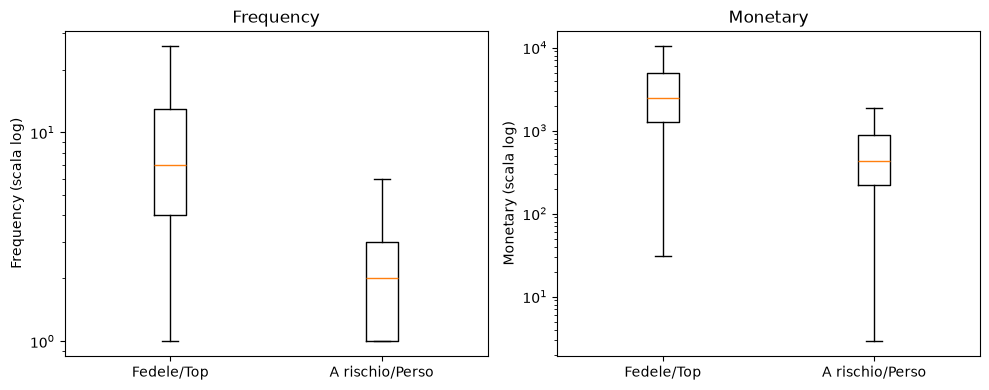

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric in zip(axes, ["Frequency", "Monetary"]):
    data = [
        rfm.loc[rfm["Gruppo"] == "Fedele/Top", metric],
        rfm.loc[rfm["Gruppo"] == "A rischio/Perso", metric],
    ]
    ax.boxplot(data, tick_labels=["Fedele/Top", "A rischio/Perso"], showfliers=False)
    ax.set_yscale("log")
    ax.set_title(metric)
    ax.set_ylabel(f"{metric} (scala log)")

plt.tight_layout()
plt.show()

## 3. Correlazioni tra Recency, Frequency e Monetary

Dato che Frequency e Monetary non sono distribuite normalmente (vedi test di Shapiro-Wilk sopra), la correlazione di **Pearson** - che misura relazioni lineari ed e' sensibile agli outlier - puo' sottostimare la reale relazione tra le variabili. Calcoliamo quindi anche la correlazione di **Spearman** (basata sui ranghi), piu' robusta in presenza di asimmetria e valori estremi, e la usiamo come riferimento principale per l'interpretazione.

In [10]:
corr_pearson = rfm[["Recency", "Frequency", "Monetary"]].corr(method="pearson")
corr_spearman = rfm[["Recency", "Frequency", "Monetary"]].corr(method="spearman")

print("Correlazione di Pearson:")
display(corr_pearson.round(3))
print()
print("Correlazione di Spearman:")
display(corr_spearman.round(3))

Correlazione di Pearson:


,Recency,Frequency,Monetary
Recency,1.000,-0.257,-0.125
Frequency,-0.257,1.000,0.637
Monetary,-0.125,0.637,1.000



Correlazione di Spearman:


,Recency,Frequency,Monetary
Recency,1.000,-0.561,-0.512
Frequency,-0.561,1.000,0.858
Monetary,-0.512,0.858,1.000


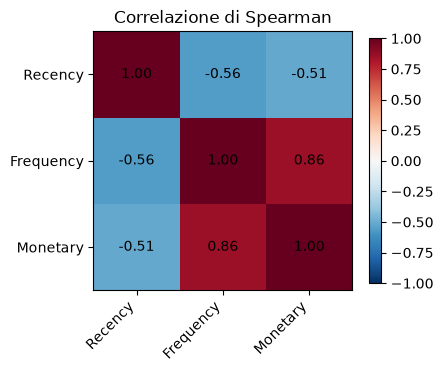

In [11]:
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(corr_spearman, vmin=-1, vmax=1, cmap="RdBu_r")

ax.set_xticks(range(len(corr_spearman.columns)))
ax.set_yticks(range(len(corr_spearman.columns)))
ax.set_xticklabels(corr_spearman.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_spearman.columns)

for i in range(len(corr_spearman)):
    for j in range(len(corr_spearman)):
        ax.text(j, i, f"{corr_spearman.iloc[i, j]:.2f}", ha="center", va="center")

ax.set_title("Correlazione di Spearman")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## 4. Cosa suggeriscono i risultati sul comportamento dei clienti a rischio di abbandono

- **Recency e' correlata negativamente sia con Frequency (Spearman ~ -0.56) sia con Monetary (Spearman ~ -0.51)**: i clienti che non acquistano da piu' tempo sono anche quelli che, storicamente, hanno acquistato meno spesso e speso meno. L'abbandono non e' quindi un evento isolato, ma tende ad accompagnarsi a un profilo di engagement gia' piu' debole.
- **Frequency e Monetary sono fortemente correlate positivamente (Spearman ~ 0.86)**: i clienti che acquistano piu' spesso sono, prevedibilmente, anche quelli che spendono di piu' in totale. Questo giustifica l'uso congiunto di Frequency e Monetary come proxy del valore del cliente nella segmentazione.
- **Il confronto statistico conferma che i segmenti non sono solo etichette arbitrarie**: la differenza tra clienti Fedele/Top e clienti A rischio/Perso su Frequency e Monetary e' altamente significativa (Mann-Whitney U, `p < 0.001` in entrambi i casi), non riconducibile al caso.
- **Implicazione operativa**: poiche' Recency, Frequency e Monetary sono correlate tra loro, un cliente che rallenta la frequenza d'acquisto (e quindi riduce anche il valore monetario) e' un candidato precoce a diventare "a rischio" anche prima che la sua Recency diventi elevata. Monitorare il calo di Frequency puo' quindi fungere da segnale di allerta anticipato rispetto all'aumento della sola Recency, utile per azioni di retention proattive sui clienti ancora nei segmenti Fedele/A rischio prima che scivolino verso Perso.